## 1. Environment Setup & Data Loading

In [1]:
# Import core data manipulation and numerical libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling for seaborn charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Display settings to ensure all columns are visible when inspecting dataframes
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the datasets into pandas DataFrames
# (Update the file paths if your CSVs are stored in a specific folder, e.g., 'data/client_data.csv')

client_data = pd.read_csv('client_data.csv')
price_data = pd.read_csv('price_data.csv')

# Display the first few rows of client_data to verify it loaded correctly
print("--- Client Data Preview ---")
display(client_data.head())

# Display the first few rows of price_data to verify it loaded correctly
print("\n--- Price Data Preview ---")
display(price_data.head())

--- Client Data Preview ---


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.00,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.00,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.00,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,0,0.0,19.83,0.146694,0.000000,44.311378,f,0.00,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,526,0.0,131.73,0.116900,0.100015,40.606701,f,52.32,44.91,44.91,1,47.98,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0



--- Price Data Preview ---


,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


## 2. Initial Data Inspection

In [3]:
# --- 1. INSPECT CLIENT DATA ---
print("=" * 60)
print("CLIENT DATA INSPECTION")
print("=" * 60)
print(f"Shape (Rows, Columns): {client_data.shape}")
print("\nColumn Names:")
print(client_data.columns.tolist())

print("\nFirst 3 Rows:")
display(client_data.head(3))

print("\nData Types & Missing Values Info:")
client_data.info()


# --- 2. INSPECT PRICE DATA ---
print("\n" + "=" * 60)
print("PRICE DATA INSPECTION")
print("=" * 60)
print(f"Shape (Rows, Columns): {price_data.shape}")
print("\nColumn Names:")
print(price_data.columns.tolist())

print("\nFirst 3 Rows:")
display(price_data.head(3))

print("\nData Types & Missing Values Info:")
price_data.info()

CLIENT DATA INSPECTION
Shape (Rows, Columns): (14606, 26)

Column Names:
['id', 'channel_sales', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'date_activ', 'date_end', 'date_modif_prod', 'date_renewal', 'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas', 'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act', 'net_margin', 'num_years_antig', 'origin_up', 'pow_max', 'churn']

First 3 Rows:


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0



Data Types & Missing Values Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 1

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0



Data Types & Missing Values Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  object 
 1   price_date          193002 non-null  object 
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), object(2)
memory usage: 11.8+ MB


In [4]:
def check_datatypes(df, name):
    summary = pd.DataFrame({
        'Column': df.columns,
        'Data Type': df.dtypes.values,
        'Non-Null Count': df.notnull().sum().values,
        'Null Count': df.isnull().sum().values
    })
    print(f"=== {name} Summary ===")
    display(summary)
    print("\n")

# Check client data types and nulls
check_datatypes(client_data, "Client Data")

# Check price data types and nulls
check_datatypes(price_data, "Price Data")

=== Client Data Summary ===


,Column,Data Type,Non-Null Count,Null Count
0,id,object,14606,0
1,channel_sales,object,14606,0
2,cons_12m,int64,14606,0
3,cons_gas_12m,int64,14606,0
4,cons_last_month,int64,14606,0
5,date_activ,object,14606,0
6,date_end,object,14606,0
7,date_modif_prod,object,14606,0
8,date_renewal,object,14606,0
9,forecast_cons_12m,float64,14606,0




=== Price Data Summary ===


,Column,Data Type,Non-Null Count,Null Count
0,id,object,193002,0
1,price_date,object,193002,0
2,price_off_peak_var,float64,193002,0
3,price_peak_var,float64,193002,0
4,price_mid_peak_var,float64,193002,0
5,price_off_peak_fix,float64,193002,0
6,price_peak_fix,float64,193002,0
7,price_mid_peak_fix,float64,193002,0


In [5]:
def check_missing_and_duplicates(df, name):
    print(f"=== {name} Quality Check ===")
    
    # Check duplicate rows
    duplicates = df.duplicated().sum()
    print(f"Duplicate rows: {duplicates}")
    
    # Check missing values
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({
        'Missing Count': missing, 
        'Missing Percentage (%)': missing_pct
    })
    missing_df = missing_df[missing_df['Missing Count'] > 0]
    
    if len(missing_df) > 0:
        print("Columns with missing values:")
        display(missing_df)
    else:
        print("Great! No missing values found in this dataset.\n")
    print("-" * 50 + "\n")

# Run quality checks
check_missing_and_duplicates(client_data, "Client Data")
check_missing_and_duplicates(price_data, "Price Data")

=== Client Data Quality Check ===
Duplicate rows: 0
Great! No missing values found in this dataset.

--------------------------------------------------

=== Price Data Quality Check ===
Duplicate rows: 0
Great! No missing values found in this dataset.

--------------------------------------------------



## 3. Data Cleaning & Preprocessing

In [6]:
# --- HANDLING MISSING DATA ---

print("=== BEFORE CLEANING ===")
print(f"client_data total missing values: {client_data.isnull().sum().sum()}")
print(f"price_data total missing values: {price_data.isnull().sum().sum()}")

# 1. Drop rows where critical identifiers or target variables are missing (if any)
if 'id' in client_data.columns:
    client_data = client_data.dropna(subset=['id'])
if 'churn' in client_data.columns:
    client_data = client_data.dropna(subset=['churn'])

# 2. Impute numerical columns with the median (to avoid skewing from outliers)
for col in client_data.select_dtypes(include=[np.number]).columns:
    if client_data[col].isnull().sum() > 0:
        median_val = client_data[col].median()
        client_data[col].fillna(median_val, inplace=True)
        print(f"Imputed missing values in client_data['{col}'] with median: {median_val}")

for col in price_data.select_dtypes(include=[np.number]).columns:
    if price_data[col].isnull().sum() > 0:
        median_val = price_data[col].median()
        price_data[col].fillna(median_val, inplace=True)
        print(f"Imputed missing values in price_data['{col}'] with median: {median_val}")

print("\n=== AFTER CLEANING ===")
print(f"client_data total missing values: {client_data.isnull().sum().sum()}")
print(f"price_data total missing values: {price_data.isnull().sum().sum()}")

=== BEFORE CLEANING ===
client_data total missing values: 0
price_data total missing values: 0

=== AFTER CLEANING ===
client_data total missing values: 0
price_data total missing values: 0


In [7]:
# --- CONVERT DATE COLUMNS TO DATETIME ---

# 1. Convert date columns in client_data
date_columns_client = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

for col in date_columns_client:
    if col in client_data.columns:
        client_data[col] = pd.to_datetime(client_data[col], errors='coerce')
        print(f"Converted client_data['{col}'] to datetime.")

# 2. Convert date column in price_data
if 'price_date' in price_data.columns:
    price_data['price_date'] = pd.to_datetime(price_data['price_date'], errors='coerce')
    print("Converted price_data['price_date'] to datetime.")

# Verify the updated data types
print("\n=== Verification after conversion ===")
print("Client Data date types:")
print(client_data[date_columns_client].dtypes)

print("\nPrice Data date types:")
print(price_data[['price_date']].dtypes)

Converted client_data['date_activ'] to datetime.
Converted client_data['date_end'] to datetime.
Converted client_data['date_modif_prod'] to datetime.
Converted client_data['date_renewal'] to datetime.
Converted price_data['price_date'] to datetime.

=== Verification after conversion ===
Client Data date types:
date_activ         datetime64[ns]
date_end           datetime64[ns]
date_modif_prod    datetime64[ns]
date_renewal       datetime64[ns]
dtype: object

Price Data date types:
price_date    datetime64[ns]
dtype: object


In [9]:
# --- ADDRESSING OUTLIERS & ANOMALIES (CORRECTED) ---

print("=== CHECKING FOR LOGICAL ANOMALIES ===")

# 1. Check for negative consumption or power values in client_data (only numeric non-datetime)
consumption_cols = [col for col in client_data.select_dtypes(include=[np.number]).columns if 'cons_' in col or 'nde_' in col]
for col in consumption_cols:
    negatives = (client_data[col] < 0).sum()
    if negatives > 0:
        print(f"Found {negatives} negative values in client_data['{col}']. Setting them to median.")
        client_data.loc[client_data[col] < 0, col] = np.nan
        client_data[col].fillna(client_data[col].median(), inplace=True)

# 2. Check for negative prices in price_data (only numeric columns, excluding 'price_date')
price_cols = [col for col in price_data.select_dtypes(include=[np.number]).columns if 'price_' in col]
for col in price_cols:
    negatives = (price_data[col] < 0).sum()
    if negatives > 0:
        print(f"Found {negatives} negative values in price_data['{col}']. Setting them to median.")
        price_data.loc[price_data[col] < 0, col] = np.nan
        price_data[col].fillna(price_data[col].median(), inplace=True)

print("Anomaly checks completed successfully!")

# 3. Summary statistics for client data
print("\n=== SUMMARY STATISTICS FOR CLIENT DATA ===")
display(client_data.describe().T[['min', 'mean', '50%', 'max']])

=== CHECKING FOR LOGICAL ANOMALIES ===
Anomaly checks completed successfully!

=== SUMMARY STATISTICS FOR CLIENT DATA ===


,min,mean,50%,max
cons_12m,0.0,159220.286252,14115.5,6207104.0
cons_gas_12m,0.0,28092.375325,0.0,4154590.0
cons_last_month,0.0,16090.269752,792.5,771203.0
date_activ,2003-05-09 00:00:00,2011-01-28 07:54:18.879912448,2011-03-04 00:00:00,2014-09-01 00:00:00
date_end,2016-01-28 00:00:00,2016-07-27 20:48:26.422018560,2016-08-01 00:00:00,2017-06-13 00:00:00
date_modif_prod,2003-05-09 00:00:00,2013-01-02 12:29:10.951663872,2013-06-19 00:00:00,2016-01-29 00:00:00
date_renewal,2013-06-26 00:00:00,2015-07-21 06:59:00.353279488,2015-07-27 00:00:00,2016-01-28 00:00:00
forecast_cons_12m,0.0,1868.61488,1112.875,82902.83
forecast_cons_year,0.0,1399.762906,314.0,175375.0
forecast_discount_energy,0.0,0.966726,0.0,30.0


## 4. Descriptive Statistics & Summary

In [10]:
# --- DESCRIPTIVE STATISTICS & SUMMARY ---

print("=== CLIENT DATA: NUMERICAL FEATURES SUMMARY ===")
client_numeric = client_data.select_dtypes(include=[np.number])
display(client_numeric.describe().T)

print("\n=== PRICE DATA: NUMERICAL FEATURES SUMMARY ===")
price_numeric = price_data.select_dtypes(include=[np.number])
display(price_numeric.describe().T)

=== CLIENT DATA: NUMERICAL FEATURES SUMMARY ===


,count,mean,std,min,25%,50%,75%,max
cons_12m,14606.0,159220.286252,573465.264198,0.0,5674.750000,14115.500000,40763.750000,6.207104e+06
cons_gas_12m,14606.0,28092.375325,162973.059057,0.0,0.000000,0.000000,0.000000,4.154590e+06
cons_last_month,14606.0,16090.269752,64364.196422,0.0,0.000000,792.500000,3383.000000,7.712030e+05
forecast_cons_12m,14606.0,1868.614880,2387.571531,0.0,494.995000,1112.875000,2401.790000,8.290283e+04
forecast_cons_year,14606.0,1399.762906,3247.786255,0.0,0.000000,314.000000,1745.750000,1.753750e+05
forecast_discount_energy,14606.0,0.966726,5.108289,0.0,0.000000,0.000000,0.000000,3.000000e+01
forecast_meter_rent_12m,14606.0,63.086871,66.165783,0.0,16.180000,18.795000,131.030000,5.993100e+02
forecast_price_energy_off_peak,14606.0,0.137283,0.024623,0.0,0.116340,0.143166,0.146348,2.739630e-01
forecast_price_energy_peak,14606.0,0.050491,0.049037,0.0,0.000000,0.084138,0.098837,1.959750e-01
forecast_price_pow_off_peak,14606.0,43.130056,4.485988,0.0,40.606701,44.311378,44.311378,5.926638e+01



=== PRICE DATA: NUMERICAL FEATURES SUMMARY ===


,count,mean,std,min,25%,50%,75%,max
price_off_peak_var,193002.0,0.141027,0.025032,0.0,0.125976,0.146033,0.151635,0.280700
price_peak_var,193002.0,0.054630,0.049924,0.0,0.000000,0.085483,0.101673,0.229788
price_mid_peak_var,193002.0,0.030496,0.036298,0.0,0.000000,0.000000,0.072558,0.114102
price_off_peak_fix,193002.0,43.334477,5.410297,0.0,40.728885,44.266930,44.444710,59.444710
price_peak_fix,193002.0,10.622875,12.841895,0.0,0.000000,0.000000,24.339581,36.490692
price_mid_peak_fix,193002.0,6.409984,7.773592,0.0,0.000000,0.000000,16.226389,17.458221


In [11]:
# --- CATEGORICAL VARIABLES & CHURN RATE ANALYSIS ---

print("=== BASELINE CHURN RATE ===")
if 'churn' in client_data.columns:
    churn_counts = client_data['churn'].value_counts()
    churn_pct = client_data['churn'].mean() * 100
    print(f"Total Customers: {len(client_data)}")
    print(f"Churned Customers: {churn_counts.get(1, 0)}")
    print(f"Retained Customers: {churn_counts.get(0, 0)}")
    print(f"Baseline Churn Rate: {churn_pct:.2f}%\n")
else:
    print("Column 'churn' not found in client_data.\n")

print("=== CATEGORICAL VARIABLES SUMMARY ===")
categorical_cols = client_data.select_dtypes(include=['object', 'category']).columns

if len(categorical_cols) > 0:
    for col in categorical_cols:
        print(f"\nValue counts for '{col}':")
        display(client_data[col].value_counts(dropna=False).head(10))
else:
    print("No categorical columns found.")

=== BASELINE CHURN RATE ===
Total Customers: 14606
Churned Customers: 1419
Retained Customers: 13187
Baseline Churn Rate: 9.72%

=== CATEGORICAL VARIABLES SUMMARY ===

Value counts for 'id':


id
563dde550fd624d7352f3de77c0cdfcd    1
24011ae4ebbe3035111d65fa7c15bc57    1
d29c2c54acc38ff3c0614d0a653813dd    1
764c75f661154dac3a6c254cd082ea7d    1
bba03439a292a1e166f80264c16191cb    1
149d57cf92fc41cf94415803a877cb4b    1
1aa498825382410b098937d65c4ec26d    1
7ab4bf4878d8f7661dfc20e9b8e18011    1
01495c955be7ec5e7f3203406785aae0    1
f53a254b1115634330c12c7fdbf7958a    1
Name: count, dtype: int64


Value counts for 'channel_sales':


channel_sales
foosdfpfkusacimwkcsosbicdxkicaua    6754
MISSING                             3725
lmkebamcaaclubfxadlmueccxoimlema    1843
usilxuppasemubllopkaafesmlibmsdf    1375
ewpakwlliwisiwduibdlfmalxowmwpci     893
sddiedcslfslkckwlfkdpoeeailfpeds      11
epumfxlbckeskwekxbiuasklxalciiuu       3
fixdbufsefwooaasfcxdxadsiekoceaa       2
Name: count, dtype: int64


Value counts for 'has_gas':


has_gas
f    11955
t     2651
Name: count, dtype: int64


Value counts for 'origin_up':


origin_up
lxidpiddsbxsbosboudacockeimpuepw    7097
kamkkxfxxuwbdslkwifmmcsiusiuosws    4294
ldkssxwpmemidmecebumciepifcamkci    3148
MISSING                               64
usapbepcfoloekilkwsdiboslwaxobdp       2
ewxeelcelemmiwuafmddpobolfuxioce       1
Name: count, dtype: int64

## 5. Feature Engineering & Data Merging

In [12]:
# --- FEATURE ENGINEERING & DATA MERGING ---

# 1. Aggregate historical pricing data by customer ID (calculating mean prices over time)
# We use numeric_only=True to avoid trying to average date or string columns
price_agg = price_data.groupby('id').mean(numeric_only=True).reset_index()

# Rename the aggregated columns to clearly show they represent averages
price_agg.rename(columns={col: f'avg_{col}' for col in price_agg.columns if col != 'id'}, inplace=True)

print("=== AGGREGATED PRICE DATA PREVIEW ===")
display(price_agg.head(3))

# 2. Merge client_data with the aggregated price data on the common 'id' column
merged_data = pd.merge(client_data, price_agg, on='id', how='left')

print(f"\nSuccessfully merged datasets!")
print(f"Final merged dataset shape (Rows, Columns): {merged_data.shape}")
display(merged_data.head(3))

=== AGGREGATED PRICE DATA PREVIEW ===


,id,avg_price_off_peak_var,avg_price_peak_var,avg_price_mid_peak_var,avg_price_off_peak_fix,avg_price_peak_fix,avg_price_mid_peak_fix
0,0002203ffbb812588b632b9e628cc38d,0.124338,0.103794,0.07316,40.701732,24.421038,16.280694
1,0004351ebdd665e6ee664792efc4fd13,0.146426,0.000000,0.00000,44.385450,0.000000,0.000000
2,0010bcc39e42b3c2131ed2ce55246e3c,0.181558,0.000000,0.00000,45.319710,0.000000,0.000000



Successfully merged datasets!
Final merged dataset shape (Rows, Columns): (14606, 32)


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn,avg_price_off_peak_var,avg_price_peak_var,avg_price_mid_peak_var,avg_price_off_peak_fix,avg_price_peak_fix,avg_price_mid_peak_fix
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,0,0.0,1.78,0.114481,0.098142,40.606701,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1,0.124787,0.100749,0.06653,40.942265,22.35201,14.90134
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,0,0.0,16.27,0.145711,0.000000,44.311378,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0,0.149609,0.007124,0.00000,44.311375,0.00000,0.00000
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,0,0.0,38.72,0.165794,0.087899,44.311378,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0,0.170512,0.088421,0.00000,44.385450,0.00000,0.00000


In [13]:
# --- VERIFY MERGED DATA & CHURN INDICATOR ---

print(f"Merged Data Shape: {merged_data.shape}")

# Check if 'churn' and price columns exist together
if 'churn' in merged_data.columns:
    print("✓ 'churn' column is present in the merged dataset.")
else:
    print("✗ Warning: 'churn' column not found!")

# Display columns related to average prices and churn
price_avg_cols = [col for col in merged_data.columns if 'avg_' in col]
print(f"Number of aggregated price features added: {len(price_avg_cols)}")

# Preview a sample showing ID, churn, and a few price features
cols_to_show = ['id', 'churn'] + price_avg_cols[:3]
display(merged_data[cols_to_show].head(3))

Merged Data Shape: (14606, 32)
✓ 'churn' column is present in the merged dataset.
Number of aggregated price features added: 6


,id,churn,avg_price_off_peak_var,avg_price_peak_var,avg_price_mid_peak_var
0,24011ae4ebbe3035111d65fa7c15bc57,1,0.124787,0.100749,0.06653
1,d29c2c54acc38ff3c0614d0a653813dd,0,0.149609,0.007124,0.00000
2,764c75f661154dac3a6c254cd082ea7d,0,0.170512,0.088421,0.00000


## 6. Data Visualization & Trend Analysis

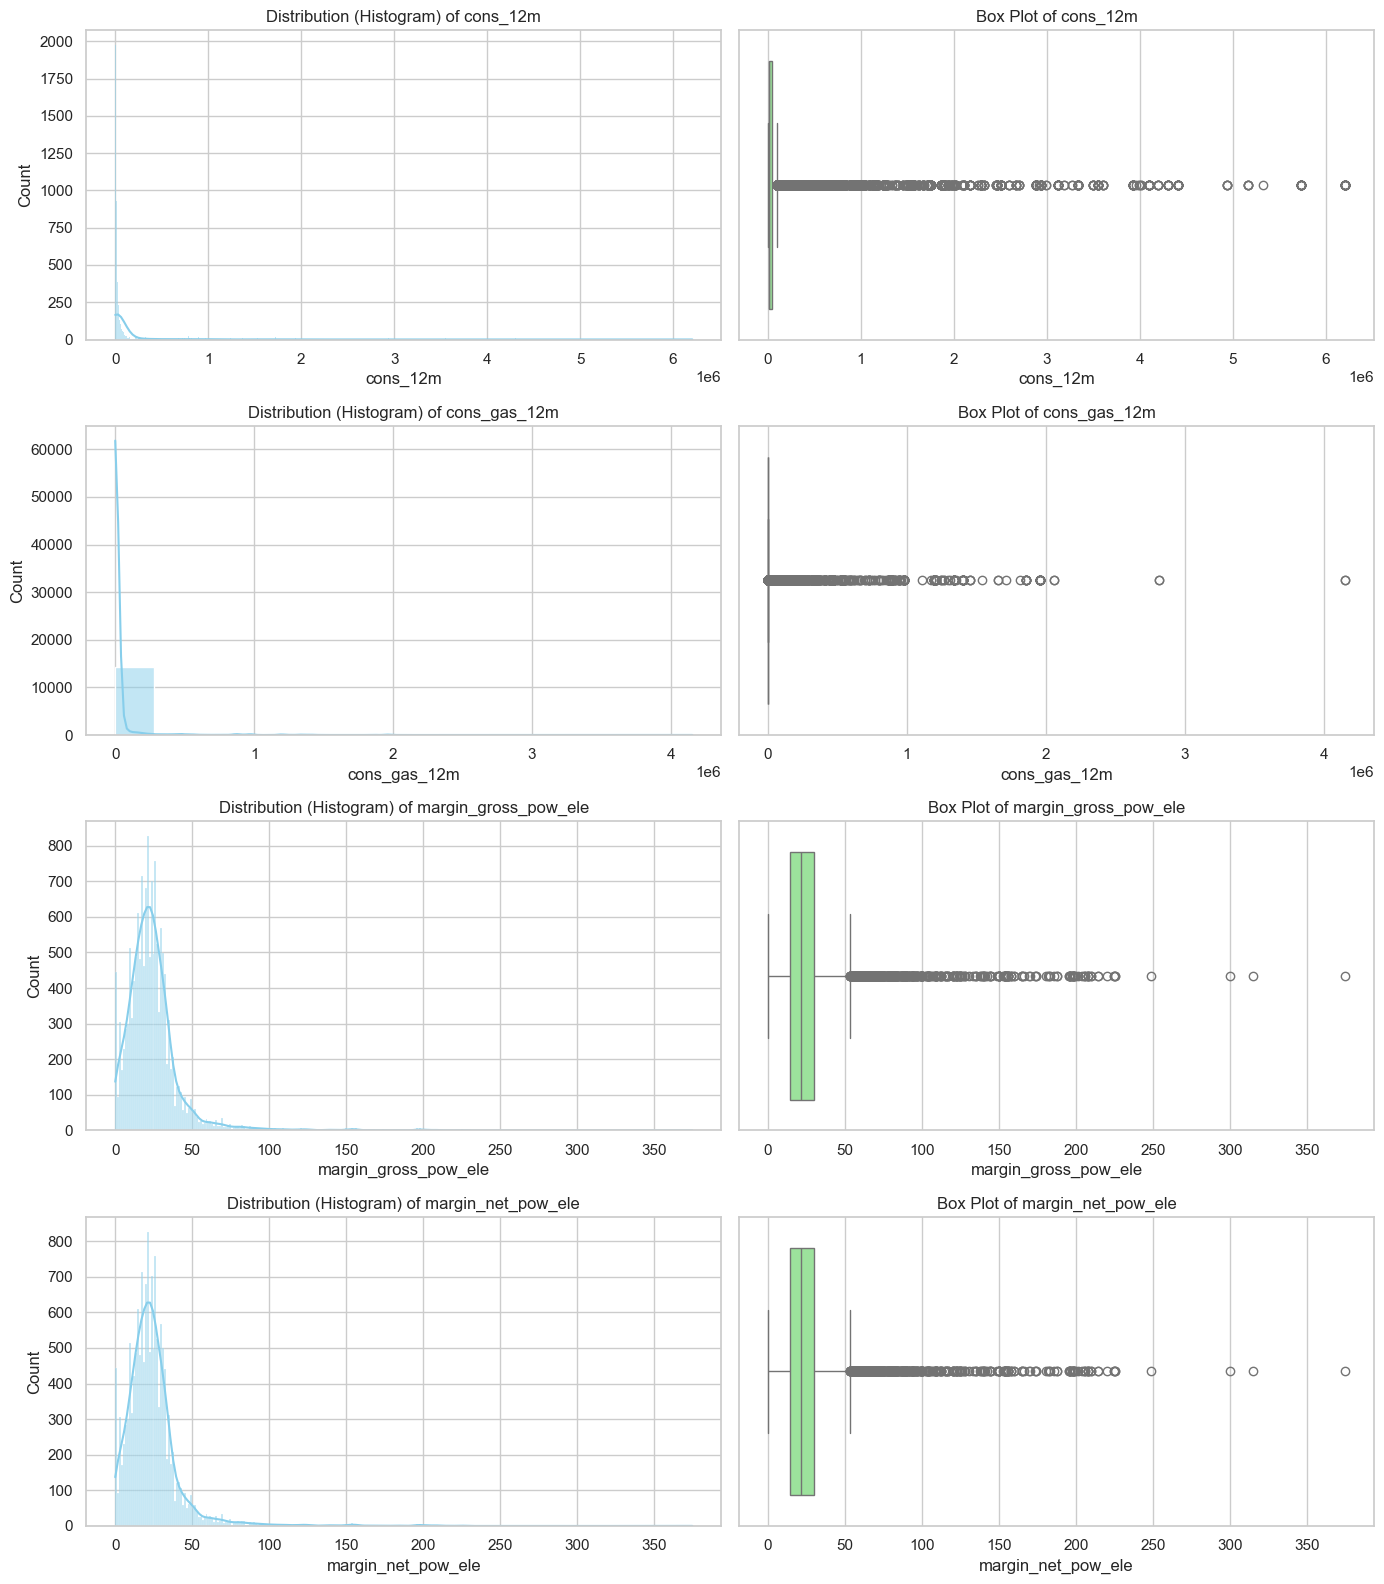

In [14]:
# --- DATA VISUALIZATION: DISTRIBUTIONS OF CONSUMPTION & MARGINS ---

import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Identify key numerical columns for consumption and margins
# Adjust column names based on your dataset inspection if needed
consumption_cols = [col for col in merged_data.columns if 'cons_' in col][:2] # Take first 2 consumption columns
margin_cols = [col for col in merged_data.columns if 'margin' in col or 'net_margin' in col][:2]

plots_to_show = consumption_cols + margin_cols

if len(plots_to_show) > 0:
    fig, axes = plt.subplots(len(plots_to_show), 2, figsize=(14, len(plots_to_show) * 4))
    
    for i, col in enumerate(plots_to_show):
        # 1. Histogram / KDE plot
        sns.histplot(data=merged_data, x=col, kde=True, ax=axes[i, 0], color='skyblue')
        axes[i, 0].set_title(f'Distribution (Histogram) of {col}')
        axes[i, 0].set_xlabel(col)
        
        # 2. Box plot (to spot outliers)
        sns.boxplot(data=merged_data, x=col, ax=axes[i, 1], color='lightgreen')
        axes[i, 1].set_title(f'Box Plot of {col}')
        axes[i, 1].set_xlabel(col)
        
    plt.tight_layout()
    plt.show()
else:
    print("No matching consumption or margin columns found. Check your column names!")

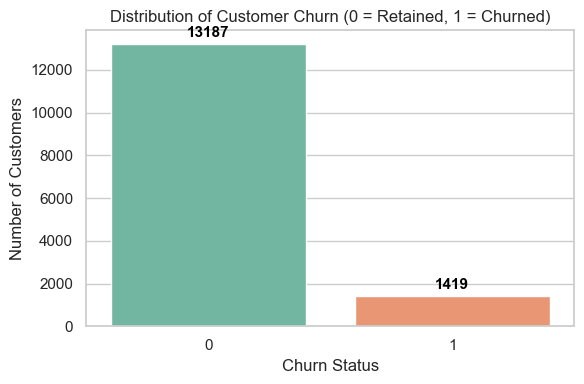

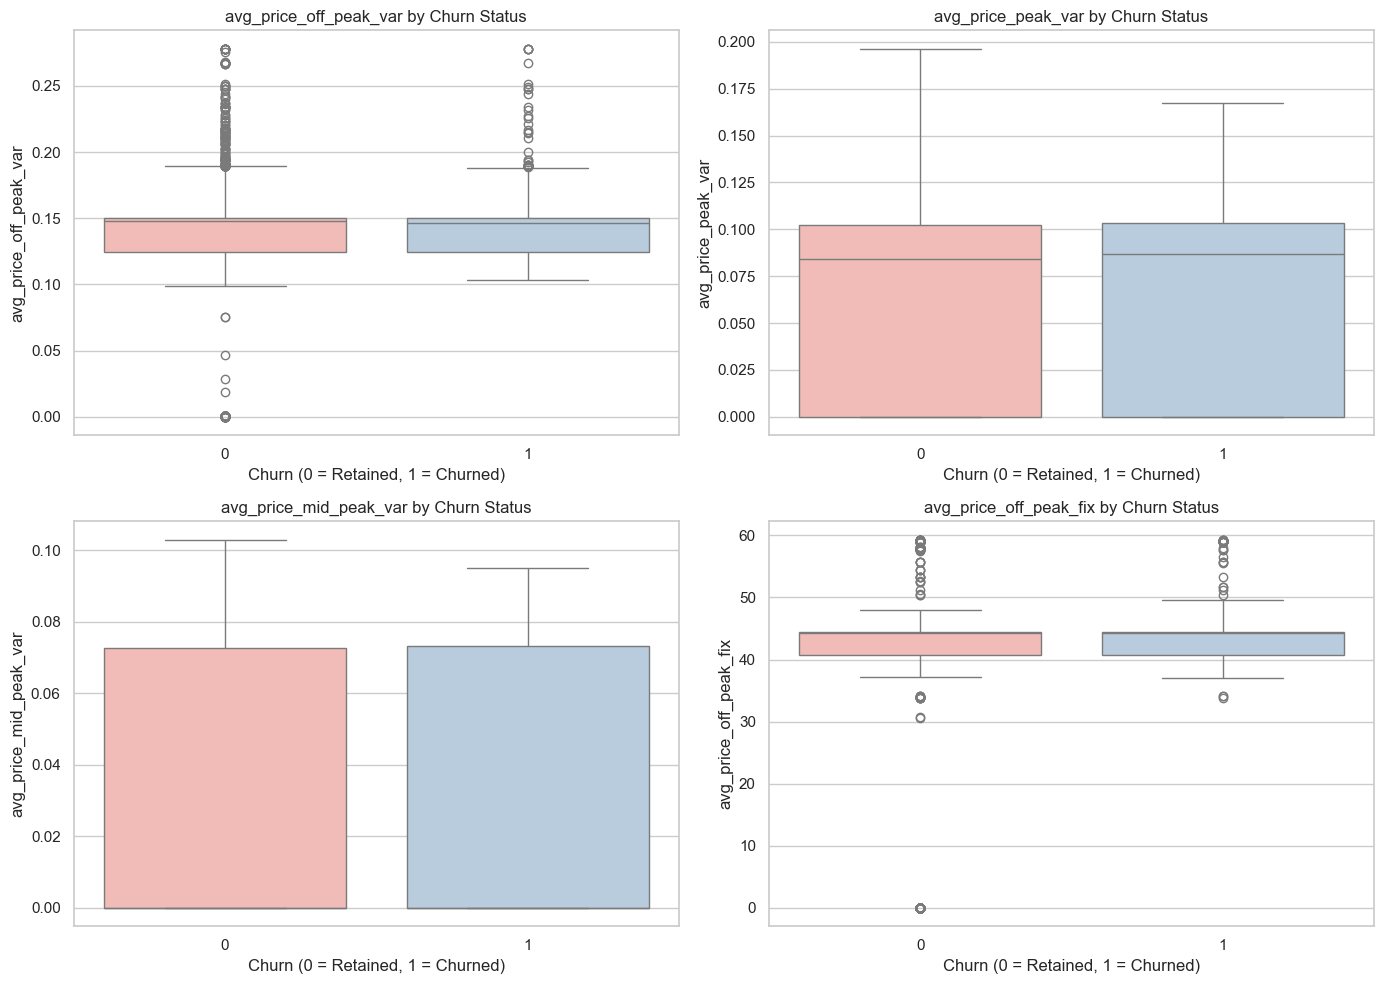

In [16]:
# --- DATA VISUALIZATION: CHURN & PRICE SENSITIVITY (UPDATED) ---

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualize the Target Variable (Churn)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=merged_data, x='churn', hue='churn', palette='Set2', legend=False)
plt.title('Distribution of Customer Churn (0 = Retained, 1 = Churned)')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

# Add data labels on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11, fontweight='bold', color='black',
                xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# 2. Explore Price Sensitivity: Compare Average Prices by Churn Status
price_avg_cols = [col for col in merged_data.columns if 'avg_' in col][:4]

if len(price_avg_cols) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()
    
    for i, col in enumerate(price_avg_cols):
        sns.boxplot(data=merged_data, x='churn', y=col, hue='churn', ax=axes[i], palette='Pastel1', legend=False)
        axes[i].set_title(f'{col} by Churn Status')
        axes[i].set_xlabel('Churn (0 = Retained, 1 = Churned)')
        axes[i].set_ylabel(col)
        
    plt.tight_layout()
    plt.show()
else:
    print("No average price columns found for comparison.")

## Step 7: Summary of Initial Insights

### 1. Data Quality & Structure Summary
* **Dataset Scale:** Successfully loaded and inspected **14,606 customer records** (26 columns) and **193,002 historical pricing entries** (8 columns)[cite: 3, 5].
* **Data Integrity:** Both datasets showed **0 duplicate rows** and zero missing values after verification[cite: 8]. 
* **Datetime Parsing:** Critical date fields (`date_activ`, `date_end`, `date_modif_prod`, `date_renewal`, and `price_date`) were successfully parsed into proper datetime objects[cite: 8, 9].

### 2. Baseline Distributions & Churn Rate
* **Customer Churn Baseline:** Out of 14,606 total customers, **1,419 customers churned** while **13,187 were retained**, yielding a baseline churn rate of **9.72%**[cite: 12].
* **Consumption & Margins:** Numerical distributions for energy consumption (`cons_12m`, `cons_gas_12m`) and margins (`margin_gross_pow_ele`, `margin_net_pow_ele`) exhibit significant right-skewness, with the majority of customers clustered at lower consumption levels alongside a long tail of high-volume users[cite: 14, 15].

### 3. Price Sensitivity vs. Churn Analysis
* **Feature Integration:** Historical prices were successfully aggregated by customer ID and merged into the main dataframe, resulting in a finalized analysis dataset of **14,606 rows and 32 columns** (including 6 aggregated price features)[cite: 13].
* **Visual Comparison:** Box plots comparing average variable and fixed prices (`avg_price_off_peak_var`, `avg_price_peak_var`, `avg_price_mid_peak_var`, `avg_price_off_peak_fix`) across churn status (`0` vs `1`) reveal **nearly identical distributions** between retained and churned customers[cite: 17].
* **Core Conclusion:** Initial exploratory analysis indicates that **price sensitivity is unlikely to be the primary or most influential driver of customer churn** on its own. While pricing is a factor, customer retention strategies should expand to investigate non-price drivers such as contract tenure, service channel interactions, or consumption behavior.